Dataset
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


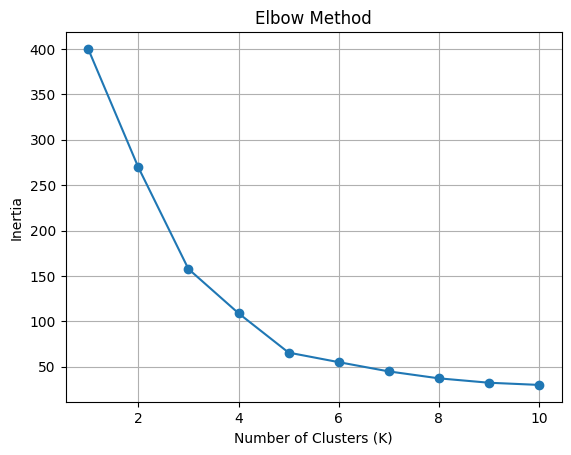


Customer cluster labels:
   CustomerID  Cluster
0           1        4
1           2        2
2           3        4
3           4        2
4           5        4
5           6        2
6           7        4
7           8        2
8           9        4
9          10        2

Cluster centroids (income, spending score):
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


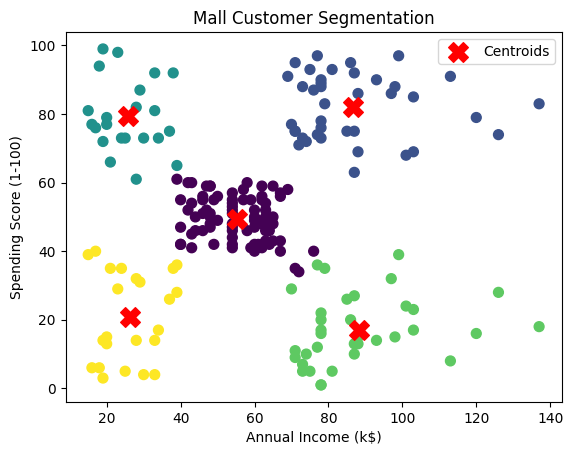


Distance from first customer to centroid 0:
1.591

Distances to all centroids:
Centroid 0 : 1.591
Centroid 1 : 3.203
Centroid 2 : 1.62
Centroid 3 : 2.92
Centroid 4 : 0.824

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Average income and spending score per cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

#dataset
df = pd.read_csv("/content/Mall_Customers.csv")
print("Dataset")
print(df.head())

#data preprocessing
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

#Select features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

#Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Elbow Method
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid()
plt.show()

#Apply K-Means
# Five clusters is a common choice; verify using the elbow graph
k = 5

model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X_scaled)

centers = model.cluster_centers_
centers_original = scaler.inverse_transform(centers)

print("\nCustomer cluster labels:")
print(df[["CustomerID", "Cluster"]].head(10))

print("\nCluster centroids (income, spending score):")
print(centers_original)

#Visualize clusters
plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segmentation")
plt.legend()
plt.show()

#Calculate Euclidean distance manually
#Use the first customer and the first centroid
point = X_scaled[0]
center = centers[0]
total = 0
for i in range(len(point)):
    difference = point[i] - center[i]
    total = total + difference * difference
distance = total ** 0.5

print("\nDistance from first customer to centroid 0:")
print(round(distance, 3))

#Calculate distance to every centroid
print("\nDistances to all centroids:")
for j in range(k):
    total = 0

    for i in range(len(point)):
        difference = point[i] - centers[j][i]
        total = total + difference * difference

    distance = total ** 0.5
    print("Centroid", j, ":", round(distance, 3))

#Analyze customer groups
print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nAverage income and spending score per cluster:")
print(df.groupby("Cluster")[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2))

